# 01 - Task 2: data preparation

Hourly weather in Hanoi from the Open-Meteo Historical Weather API (ERA5 reanalysis), 2016-2025. The target (`pred_column`) is the air temperature at 2 m. Task 2 forecasts it for the next five hours (t+1 ... t+5).

This notebook downloads and checks the data, prepares the input features, looks at the main patterns, splits the data by time into train / validation / test, builds the input windows, and computes a persistence baseline that the models have to beat.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import FEATURES, FIGURES_DIR, HORIZON, N_STEPS, REPORTS_DIR
from src.metrics import multistep_metrics
from src.weather_data import add_features, inverse_target, load_weather, prepare_forecast_data, split_by_time

FIG_DIR = FIGURES_DIR / "forecast"
FIG_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(exist_ok=True)
%matplotlib inline

## 1. Data

`load_weather()` reads `data/hanoi_weather_hourly_2016_2025.csv` and downloads it from Open-Meteo first if the file is missing. The requested point is central Hanoi (21.03°N, 105.85°E); Open-Meteo returns the nearest ERA5 grid cell. The values come from a weather reanalysis model, not directly from a measuring station.

| Column | Meaning | Unit |
|---|---|---|
| `temp` | air temperature at 2 m (**pred_column**) | °C |
| `humidity` | relative humidity at 2 m | % |
| `dew_point` | dew point at 2 m | °C |
| `pressure` | surface pressure | hPa |
| `precipitation` | precipitation during the hour | mm |
| `cloud_cover` | total cloud cover | % |
| `wind_speed` | wind speed at 10 m | km/h |
| `wind_dir` | wind direction at 10 m | degrees |

In [2]:
df = load_weather()
print(f"{len(df):,} rows x {df.shape[1]} columns | {df['time'].min()} -> {df['time'].max()}")
df.head()

87,672 rows x 9 columns | 2016-01-01 00:00:00 -> 2025-12-31 23:00:00


,time,temp,humidity,dew_point,pressure,precipitation,cloud_cover,wind_speed,wind_dir
0,2016-01-01 00:00:00,15.1,74,10.5,1025.0,0.0,99,3.3,347
1,2016-01-01 01:00:00,14.9,75,10.6,1024.3,0.0,99,2.9,353
2,2016-01-01 02:00:00,14.9,75,10.6,1023.5,0.0,99,2.2,360
3,2016-01-01 03:00:00,15.0,73,10.2,1022.8,0.0,98,2.5,8
4,2016-01-01 04:00:00,14.6,75,10.3,1022.5,0.0,95,3.0,14


In [3]:
# kiểm tra chất lượng: giá trị thiếu, giờ bị lặp, khoảng cách giữa hai dòng liên tiếp
print("missing values:", int(df.isna().sum().sum()))
print("duplicate timestamps:", int(df["time"].duplicated().sum()))
print("time step between rows:", df["time"].diff().dropna().value_counts().to_dict())
df.describe().T.round(2)

missing values: 0
duplicate timestamps: 0
time step between rows: {Timedelta('0 days 01:00:00'): 87671}


,count,mean,min,25%,50%,75%,max,std
time,87672,2020-12-31 11:30:00,2016-01-01 00:00:00,2018-07-02 05:45:00,2020-12-31 11:30:00,2023-07-02 17:15:00,2025-12-31 23:00:00,NaN
temp,87672.0,24.109431,4.4,20.3,25.0,28.025,40.2,5.543477
humidity,87672.0,79.64512,21.0,70.0,82.0,92.0,100.0,14.293861
dew_point,87672.0,20.106724,-8.4,16.3,22.2,25.1,30.4,6.209974
pressure,87672.0,1008.884877,979.9,1002.9,1008.5,1014.5,1038.9,7.380829
precipitation,87672.0,0.25124,0.0,0.0,0.0,0.1,28.8,1.009569
cloud_cover,87672.0,73.724074,0.0,46.0,98.0,100.0,100.0,35.906351
wind_speed,87672.0,9.250111,0.0,5.8,8.7,12.2,62.4,4.579284
wind_dir,87672.0,139.027455,1.0,58.0,133.0,167.0,360.0,97.271551


The data are complete: no missing values, no repeated hours and exactly one hour between consecutive rows, so no cleaning or filling is needed.

## 2. Features

Wind direction is an angle: 359° and 1° are almost the same direction but far apart as numbers, so it is replaced by its sine and cosine (`wind_dir_cos` = 1 for wind from the north, -1 from the south; `wind_dir_sin` = 1 from the east, -1 from the west). The model input therefore has 9 columns, including the past temperature itself. In the model notebooks all of them are scaled to [0, 1] with `MinMaxScaler`, fitted on the training period only.

In [4]:
dff = add_features(df)
print(len(FEATURES), "input features:", FEATURES)
dff[["time"] + FEATURES].head()

9 input features: ['temp', 'humidity', 'dew_point', 'pressure', 'precipitation', 'cloud_cover', 'wind_speed', 'wind_dir_sin', 'wind_dir_cos']


,time,temp,humidity,dew_point,pressure,precipitation,cloud_cover,wind_speed,wind_dir_sin,wind_dir_cos
0,2016-01-01 00:00:00,15.1,74,10.5,1025.0,0.0,99,3.3,-2.249511e-01,0.974370
1,2016-01-01 01:00:00,14.9,75,10.6,1024.3,0.0,99,2.9,-1.218693e-01,0.992546
2,2016-01-01 02:00:00,14.9,75,10.6,1023.5,0.0,99,2.2,-2.449294e-16,1.000000
3,2016-01-01 03:00:00,15.0,73,10.2,1022.8,0.0,98,2.5,1.391731e-01,0.990268
4,2016-01-01 04:00:00,14.6,75,10.3,1022.5,0.0,95,3.0,2.419219e-01,0.970296


## 3. Exploratory analysis

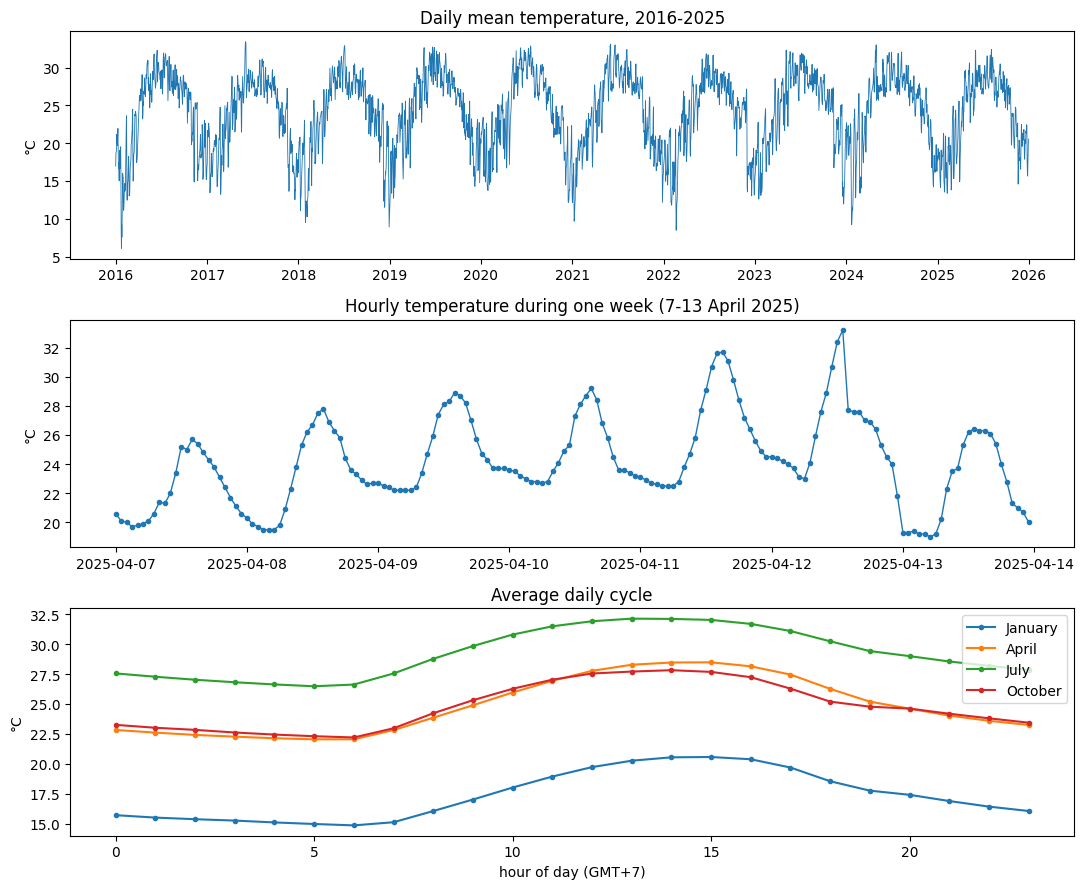

mean temperature by month (°C): {1: 17.3, 2: 18.3, 3: 21.7, 4: 24.8, 5: 27.6, 6: 29.5, 7: 29.2, 8: 28.4, 9: 27.5, 10: 24.8, 11: 22.0, 12: 18.0}
mean daily range (max - min within a day): 6.7 °C
coldest hour on average: 6 h | warmest hour: 14 h


In [5]:
fig, axes = plt.subplots(3, 1, figsize=(11, 9))

daily = df.set_index("time")["temp"].resample("D").mean()
axes[0].plot(daily.index, daily.values, lw=0.6)
axes[0].set_title("Daily mean temperature, 2016-2025")
axes[0].set_ylabel("°C")

week = df[(df["time"] >= "2025-04-07") & (df["time"] < "2025-04-14")]
axes[1].plot(week["time"], week["temp"], marker=".", lw=1)
axes[1].set_title("Hourly temperature during one week (7-13 April 2025)")
axes[1].set_ylabel("°C")

# đường nhiệt độ trung bình theo giờ trong ngày, cho 4 tháng đại diện 4 mùa
cycle = df.assign(month=df["time"].dt.month, hour=df["time"].dt.hour).pivot_table(index="hour", columns="month", values="temp")
for month, name in [(1, "January"), (4, "April"), (7, "July"), (10, "October")]:
    axes[2].plot(cycle.index, cycle[month], marker=".", label=name)
axes[2].set_title("Average daily cycle")
axes[2].set_xlabel("hour of day (GMT+7)")
axes[2].set_ylabel("°C")
axes[2].legend()

plt.tight_layout()
fig.savefig(FIG_DIR / "temperature_overview.png", dpi=150, bbox_inches="tight")
plt.show()

monthly = df.groupby(df["time"].dt.month)["temp"].mean()
daily_range = df.set_index("time")["temp"].resample("D").agg(lambda s: s.max() - s.min())
print("mean temperature by month (°C):", monthly.round(1).to_dict())
print(f"mean daily range (max - min within a day): {daily_range.mean():.1f} °C")
print("coldest hour on average:", cycle.mean(axis=1).idxmin(), "h | warmest hour:", cycle.mean(axis=1).idxmax(), "h")

- **Yearly cycle:** the monthly mean goes from 17.3 °C in January to 29.5 °C in June.
- **Daily cycle:** on average the coldest hour is 6 h and the warmest is 14 h, and temperature changes by 6.7 °C within a day.
- **Sudden changes:** on 12 April 2025 the temperature fell by about 6 °C within an hour in the afternoon (rain or a cold front). Changes like this are the hard part of the forecast.

The model therefore needs at least one full day of history to know where it is in the daily cycle.

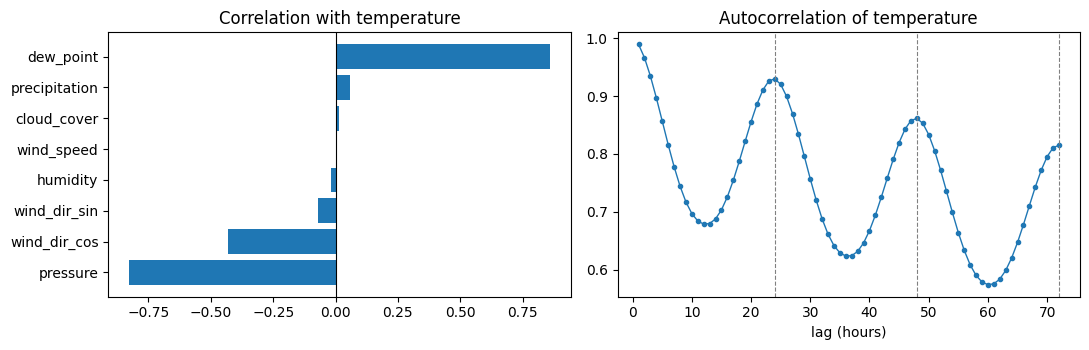

{'pressure': -0.827, 'wind_dir_cos': -0.429, 'wind_dir_sin': -0.069, 'humidity': -0.019, 'wind_speed': 0.008, 'cloud_cover': 0.015, 'precipitation': 0.058, 'dew_point': 0.859}
autocorrelation: {'lag 1': 0.989, 'lag 2': 0.966, 'lag 5': 0.857, 'lag 12': 0.679, 'lag 24': 0.93, 'lag 48': 0.861}


In [6]:
corr = dff.drop(columns="time")[FEATURES].corr()["temp"].drop("temp").sort_values()
lags = np.arange(1, 73)
acf = np.array([df["temp"].autocorr(lag) for lag in lags])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].barh(corr.index, corr.values)
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_title("Correlation with temperature")
axes[1].plot(lags, acf, marker=".", lw=1)
for lag in (24, 48, 72):
    axes[1].axvline(lag, color="grey", ls="--", lw=0.8)
axes[1].set_title("Autocorrelation of temperature")
axes[1].set_xlabel("lag (hours)")
plt.tight_layout()
fig.savefig(FIG_DIR / "correlation_autocorrelation.png", dpi=150, bbox_inches="tight")
plt.show()

print(corr.round(3).to_dict())
print("autocorrelation:", {f"lag {k}": round(float(acf[k - 1]), 3) for k in (1, 2, 5, 12, 24, 48)})

- Temperature is strongly correlated with the dew point (0.86) and negatively with pressure (-0.83, pressure is higher in the cool season). `wind_dir_cos` is also negative (-0.43): wind from the north comes with lower temperatures (the winter north-east monsoon), wind from the south with higher ones. The other variables have almost no linear correlation with temperature over the whole year, but they can still matter hour by hour (for example clouds and rain cool the air).
- The autocorrelation falls from 0.99 at 1 hour to 0.68 at 12 hours and rises again to 0.93 at 24 hours: the temperature one day earlier at the same hour is very informative. This is why each input window covers 24 hours (`N_STEPS = 24`), and why an attention layer, which can give a different weight to each of the 24 hours, suits this data.

## 4. Chronological split

A time series must not be shuffled before splitting, otherwise the model would see hours from the "future" during training. As in the lecturer's notebook, the first 70 % of the hours are used for training, the next 15 % for validation (early stopping, choosing settings) and the last 15 % for the final test. Windows are made inside each part separately, so no window crosses from one part into another.

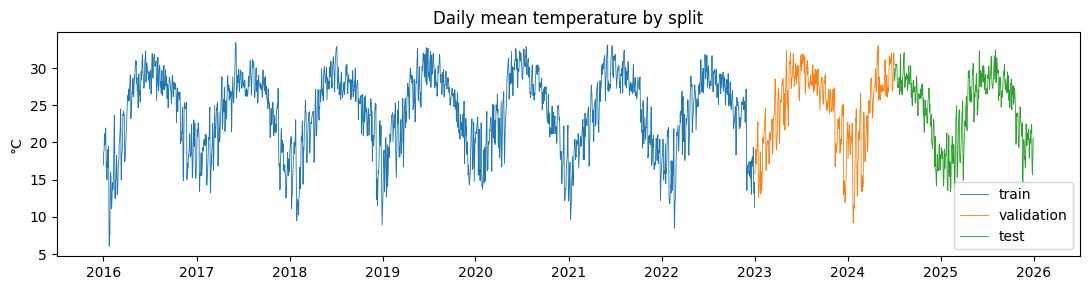

,rows,start,end,mean temp (°C)
train,61370,2016-01-01 00:00:00,2023-01-01 01:00:00,24.0
validation,13151,2023-01-01 02:00:00,2024-07-02 00:00:00,24.36
test,13151,2024-07-02 01:00:00,2025-12-31 23:00:00,24.39


In [7]:
train, val, test = split_by_time(dff)
split_info = pd.DataFrame({
    name: {"rows": len(part), "start": part["time"].min(), "end": part["time"].max(),
           "mean temp (°C)": round(part["temp"].mean(), 2)}
    for name, part in [("train", train), ("validation", val), ("test", test)]
}).T
split_info.to_csv(REPORTS_DIR / "forecast_split.csv", index_label="split")

fig, ax = plt.subplots(figsize=(11, 3))
for name, part in [("train", train), ("validation", val), ("test", test)]:
    d = part.set_index("time")["temp"].resample("D").mean()
    ax.plot(d.index, d.values, lw=0.6, label=name)
ax.set_title("Daily mean temperature by split")
ax.set_ylabel("°C")
ax.legend()
plt.tight_layout()
fig.savefig(FIG_DIR / "split.png", dpi=150, bbox_inches="tight")
plt.show()
split_info

## 5. Input windows

Each sample uses the last `N_STEPS = 24` hours (t-23 ... t) of the 9 features, i.e. one full daily cycle, and the target is the temperature at **t+1, t+2, t+3, t+4, t+5**. We read "the next five consecutive time steps, starting from the current time step" as the five hours after the current hour t, as in the lecturer's encoder-decoder notebook.

In [8]:
data = prepare_forecast_data(N_STEPS, HORIZON)
pd.DataFrame({part: {"X": str(data[f"X_{part}"].shape), "y": str(data[f"y_{part}"].shape)}
              for part in ["train", "val", "test"]}).T

,X,y
train,"(61342, 24, 9)","(61342, 5)"
val,"(13123, 24, 9)","(13123, 5)"
test,"(13123, 24, 9)","(13123, 5)"


In [9]:
# ví dụ: mẫu đầu tiên của tập test
sc, ti = data["scaler"], data["target_idx"]
t0 = pd.Timestamp(data["t_test"][0])
hour = pd.Timedelta(hours=1)
print(f"input window: {t0 - 23 * hour} ... {t0} (24 hours x {len(FEATURES)} features)")
print(f"targets     : {t0 + hour} ... {t0 + 5 * hour} -> {np.round(inverse_target(data['y_test'][0], sc, ti), 1).tolist()} °C")

input window: 2024-07-02 01:00:00 ... 2024-07-03 00:00:00 (24 hours x 9 features)
targets     : 2024-07-03 01:00:00 ... 2024-07-03 05:00:00 -> [25.6, 25.8, 25.8, 25.9, 26.2] °C


`X` has the shape `(samples, 24, 9)` = `[samples, timesteps, features]`, the input format of the Keras recurrent layers used in the lecturer's code; `y` has the shape `(samples, 5)`.

## 6. Persistence baseline

The simplest possible forecast is "the temperature in h hours equals the temperature now". A neural network is only useful if it does better than this. The baseline is evaluated in °C with the metrics from `src/metrics.py`: R² is the squared Pearson correlation and NSE = 1 - SSE/SST, as defined on the lecturer's slide (Chapter 2.1). Each horizon is evaluated separately, then the five horizons are combined in two ways: the mean of the five values ("mean of steps") and one value computed on all predictions together ("all steps").

In [10]:
rows = []
for part in ["val", "test"]:
    y_true = inverse_target(data[f"y_{part}"], sc, ti)
    now = inverse_target(data[f"X_{part}"][:, -1, ti], sc, ti)  # nhiệt độ tại thời điểm t
    y_pred = np.repeat(now[:, None], HORIZON, axis=1)
    table = multistep_metrics(y_true, y_pred)
    table.insert(0, "split", part)
    rows.append(table)

baseline = pd.concat(rows).round(3)
baseline.to_csv(REPORTS_DIR / "forecast_baseline_persistence.csv", index_label="horizon")
baseline

,split,R2,NSE,MAE,RMSE
t+1,val,0.977,0.977,0.625,0.860
t+2,val,0.928,0.926,1.155,1.527
t+3,val,0.862,0.857,1.648,2.124
t+4,val,0.788,0.775,2.101,2.662
t+5,val,0.712,0.687,2.516,3.142
mean of steps,val,0.853,0.844,1.609,2.063
all steps,val,0.851,0.844,1.609,2.215
t+1,test,0.972,0.971,0.640,0.887
t+2,test,0.913,0.911,1.179,1.567
t+3,test,0.837,0.830,1.672,2.164


## Summary

- 87,672 hourly rows, no missing values and no missing hours.
- Split by time: train 61,370 hours (2016-01-01 to 2023-01-01), validation 13,151 hours (to 2024-07-02), test 13,151 hours (2024-07-02 to 2025-12-31).
- Windows: 24 hours x 9 features as input, the temperature at t+1 ... t+5 as output.
- Persistence baseline on the test set: NSE falls from 0.971 at t+1 to 0.635 at t+5 (0.817 over all steps). The models in notebook 02 are compared with these numbers in notebook 03.